# Object Counting
Coins / RGB

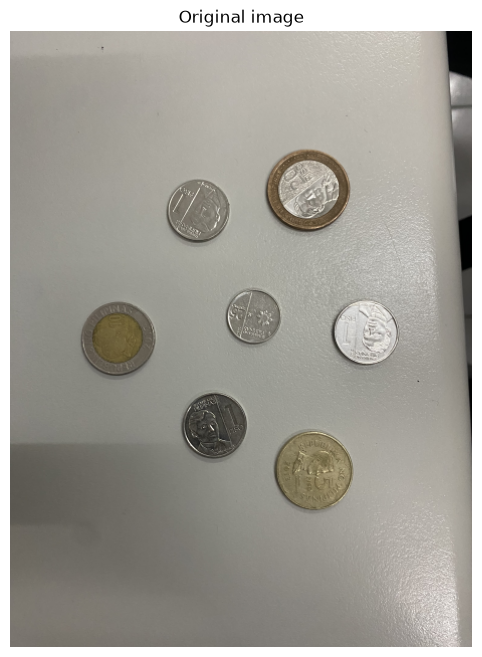

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.measure import label, regionprops
from skimage.morphology import disk, opening

# Load image
image = cv2.imread('coins.jpg')
if image is None:
    raise FileNotFoundError("Image not found.")

# Resize to a fixed width so the area thresholds below work for any photo size
new_w = 460
new_h = int(image.shape[0] * new_w / image.shape[1])
image = cv2.resize(image, (new_w, new_h), interpolation=cv2.INTER_AREA)

# Convert to RGB
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(6, 8))
plt.imshow(image_rgb)
plt.title("Original image")
plt.axis("off")
plt.show()

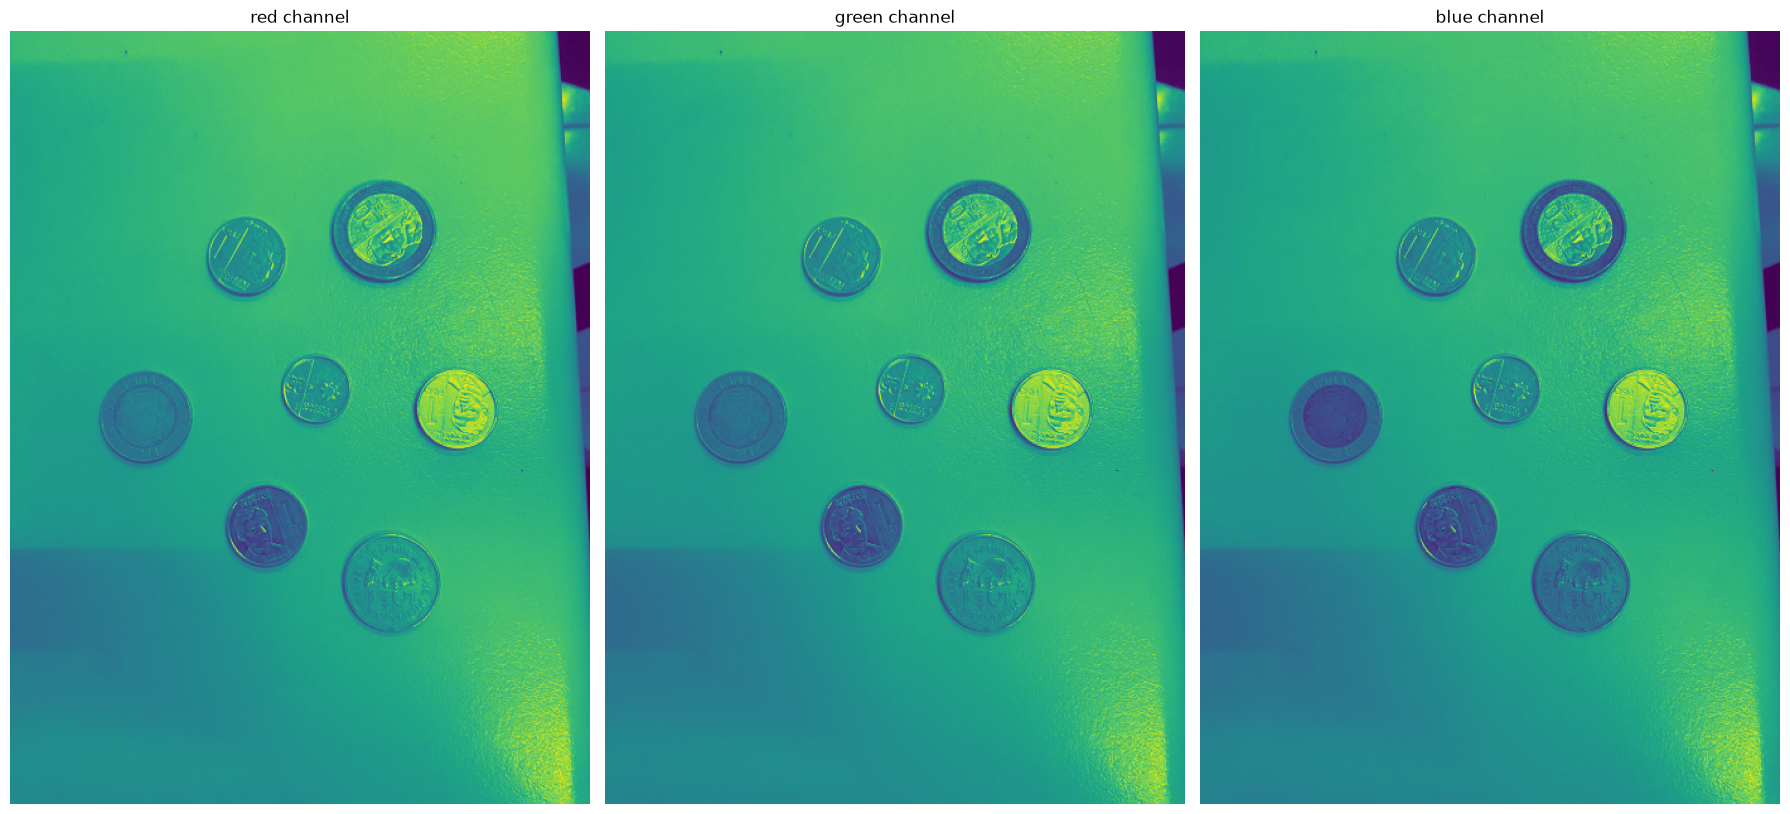

In [2]:
# Extract channels
rmat = image_rgb[:, :, 0]
gmat = image_rgb[:, :, 1]
bmat = image_rgb[:, :, 2]

# Show image for each channel
fig, axs = plt.subplots(1, 3, figsize=(18, 12))
axs[0].imshow(rmat)
axs[0].set_title("red channel")
axs[0].axis("off")

axs[1].imshow(gmat)
axs[1].set_title("green channel")
axs[1].axis("off")

axs[2].imshow(bmat)
axs[2].set_title("blue channel")
axs[2].axis("off")

plt.tight_layout()
plt.show()

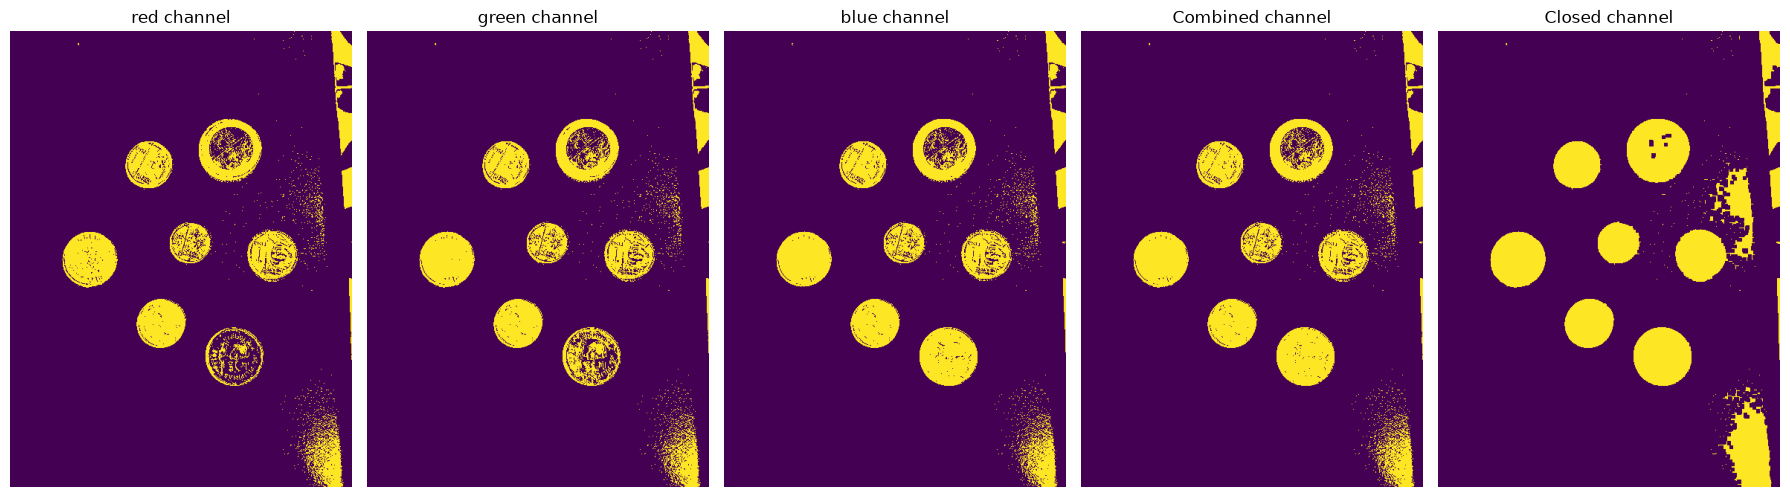

In [3]:
# The lighting in this photo is uneven (there is a shadow and a bright side),
# so one fixed threshold level per channel does not work here.
# Instead, estimate the background of each channel with a large median blur
# (the blur is bigger than a coin, so the coins disappear and only the table is left),
# then mark pixels that differ from that background.
blur_size = 121     # must be odd and bigger than the biggest coin
diff_level = 25     # how different from the background a pixel must be

def differs_from_background(channel):
    background = cv2.medianBlur(channel, blur_size)
    diff = np.abs(channel.astype(np.int16) - background.astype(np.int16))
    return (diff > diff_level).astype(np.uint8)

# Threshold RGB channels
Ired = differs_from_background(rmat)
Igreen = differs_from_background(gmat)
Iblue = differs_from_background(bmat)

# Combine channels (a pixel is an object if ANY channel differs from the background)
It = cv2.bitwise_or(cv2.bitwise_or(Ired, Igreen), Iblue)

# Close small gaps in the coin edges
Icomp = cv2.morphologyEx(It, cv2.MORPH_CLOSE, np.ones((5, 5), np.uint8))
Icomp = Icomp * 255

# Show image for each channel
fig, axs = plt.subplots(1, 5, figsize=(18, 12))
axs[0].imshow(Ired)
axs[0].set_title("red channel")
axs[0].axis("off")

axs[1].imshow(Igreen)
axs[1].set_title("green channel")
axs[1].axis("off")

axs[2].imshow(Iblue)
axs[2].set_title("blue channel")
axs[2].axis("off")

axs[3].imshow(It)
axs[3].set_title("Combined channel")
axs[3].axis("off")

axs[4].imshow(Icomp)
axs[4].set_title("Closed channel")
axs[4].axis("off")

plt.tight_layout()
plt.show()

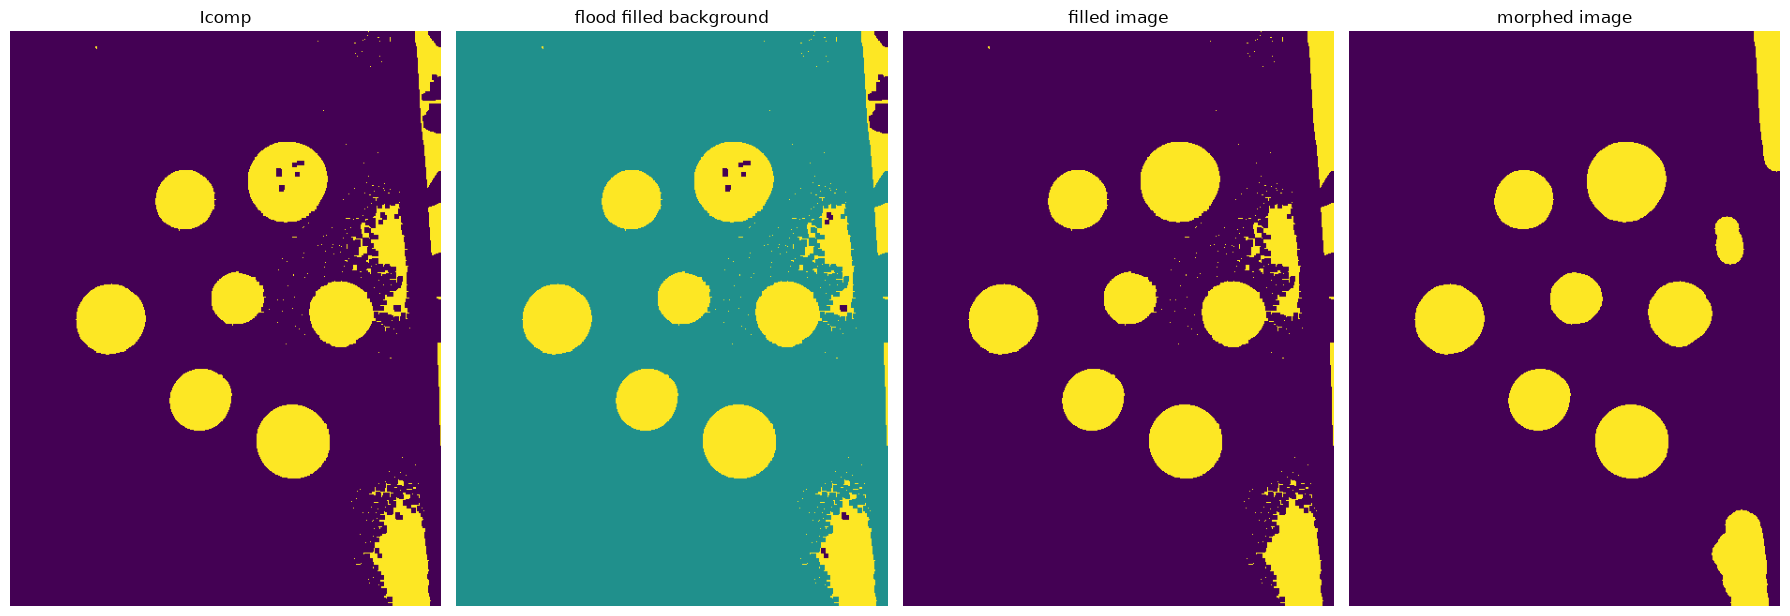

5702.0
3159.0
2419.0
3659.0
4330.0
3427.0
4888.0


In [4]:
# Fill holes
flood_fill = Icomp.copy()
h, w = flood_fill.shape
mask = np.zeros((h + 2, w + 2), np.uint8)
cv2.floodFill(flood_fill, mask, (0, 0), 128)           # fill the background with 128
filled = (flood_fill != 128).astype(np.uint8)           # everything not background = object (holes included)

# Morphological open
opened = opening(filled, disk(13)).astype(np.uint8)

# Label connected components
label_image = label(opened)
regions = regionprops(label_image)

# Show image for each step
fig, axs = plt.subplots(1, 4, figsize=(18, 12))
axs[0].imshow(Icomp)
axs[0].set_title("Icomp")
axs[0].axis("off")

axs[1].imshow(flood_fill)
axs[1].set_title("flood filled background")
axs[1].axis("off")

axs[2].imshow(filled)
axs[2].set_title("filled image")
axs[2].axis("off")

axs[3].imshow(opened)
axs[3].set_title("morphed image")
axs[3].axis("off")

plt.tight_layout()
plt.show()

# Keep only blobs that look like coins:
# - not touching the image border (that is just the edge of the table)
# - roughly round: the bounding box is almost a square, and the blob fills
#   about pi/4 (0.785) of its box
coin_regions = []
for region in regions:
    minr, minc, maxr, maxc = region.bbox
    if minr == 0 or minc == 0 or maxr == h or maxc == w:
        continue
    box_h = maxr - minr
    box_w = maxc - minc
    aspect = box_w / box_h
    if aspect < 0.8 or aspect > 1.25:
        continue
    if region.extent < 0.7:
        continue
    coin_regions.append(region)

for region in coin_regions:
    print(region.area)

In [5]:
# Classify objects (by area)
cents, one, five, ten, bente = [], [], [], [], []
for region in coin_regions:
    area = region.area
    if area < 2900:
        cents.append(region)
    elif area < 4000:
        one.append(region)
    elif area < 4700:
        ten.append(region)
    elif area < 5300:
        five.append(region)
    else:
        bente.append(region)

# Draw boxes on copy of image
output_img = image_rgb.copy()

def draw(regions_list, label_text, color):
    for region in regions_list:
        minr, minc, maxr, maxc = region.bbox
        cv2.rectangle(output_img, (minc, minr), (maxc, maxr), color, 2)
        cv2.putText(output_img, label_text, (minc, minr - 5),
                    cv2.FONT_HERSHEY_SIMPLEX, 0.6, (0, 0, 0), 2)

draw(cents, '25 Cents', (255, 0, 0))
draw(one,   '1 Peso',   (0, 255, 0))
draw(five,  '5 Peso',   (0, 0, 255))
draw(ten,   '10 Peso',  (0, 255, 0))
draw(bente, '20 Peso',  (0, 0, 255))

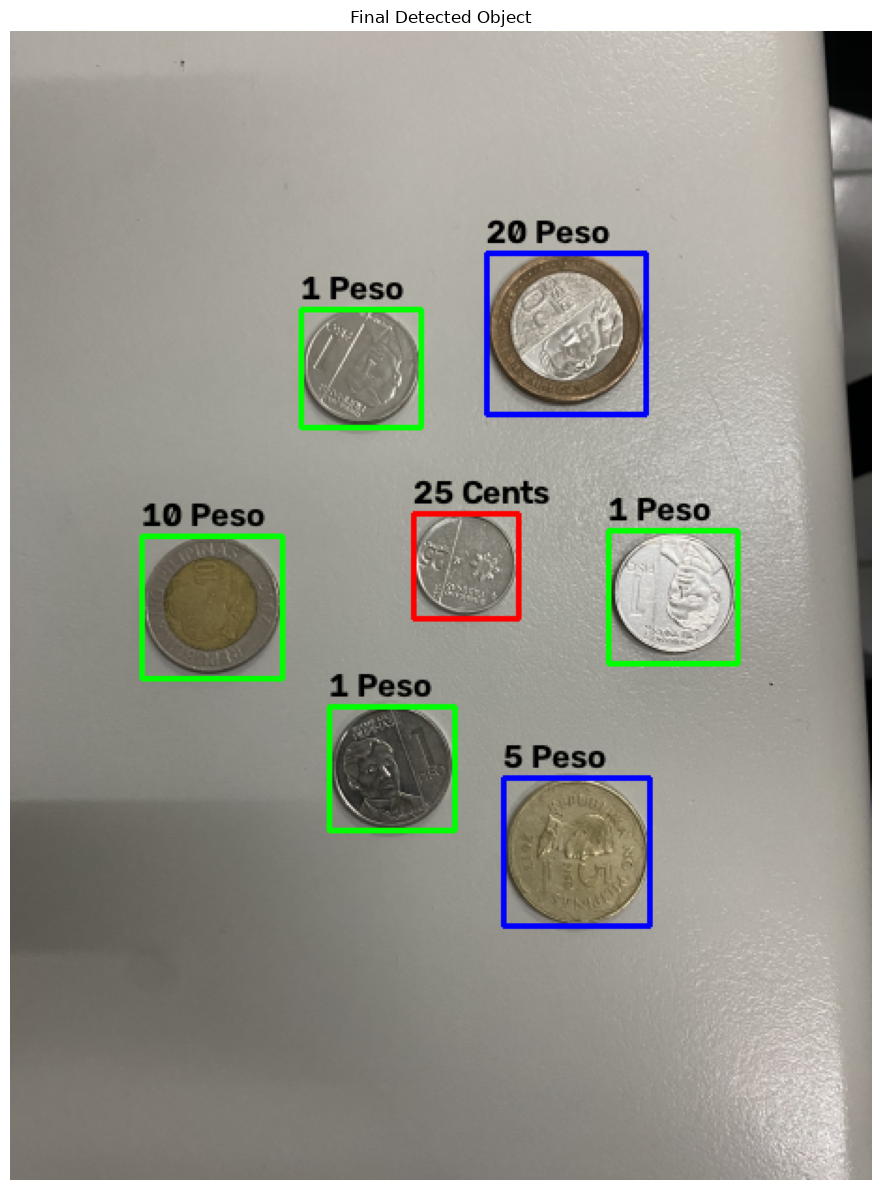

25 Cents: 1
1 Peso: 3
5 Peso: 1
10 Peso: 1
20 Peso: 1
count: 7
total value: PHP 38.25


In [6]:
# Display results
fig, axs = plt.subplots(1, 1, figsize=(10, 12))

axs.imshow(output_img)
axs.set_title("Final Detected Object")
axs.axis("off")

plt.tight_layout()
plt.show()

# Display total value
total_count = len(cents) + len(one) + len(five) + len(ten) + len(bente)
total_value = len(cents) * 0.25 + len(one) * 1 + len(five) * 5 + len(ten) * 10 + len(bente) * 20

print(f"25 Cents: {len(cents)}")
print(f"1 Peso: {len(one)}")
print(f"5 Peso: {len(five)}")
print(f"10 Peso: {len(ten)}")
print(f"20 Peso: {len(bente)}")
print(f"count: {total_count}")
print(f"total value: PHP {total_value:.2f}")